# import the important libraries

In [64]:
import pandas as pd
print(pd.__version__)
import numpy as np
print(np.__version__)
import matplotlib 
import matplotlib.pyplot as plt
print(matplotlib.__version__)
import seaborn as sns
print(sns.__version__)

3.0.2
2.4.4
3.10.8
0.13.2


# read the dataset

In [65]:
ds = pd.read_csv(r'E:\Datasets\players_22\players_22.csv', low_memory=False)

# Explore Dataset

In [66]:
print(ds.shape[0])
print(ds.shape[1])

19239
110


In [67]:
with pd.option_context('display.max_columns', None, 'display.max_rows', None):
    print(ds.head(10))

   sofifa_id                                         player_url  \
0     158023  https://sofifa.com/player/158023/lionel-messi/...   
1     188545  https://sofifa.com/player/188545/robert-lewand...   
2      20801  https://sofifa.com/player/20801/c-ronaldo-dos-...   
3     190871  https://sofifa.com/player/190871/neymar-da-sil...   
4     192985  https://sofifa.com/player/192985/kevin-de-bruy...   
5     200389  https://sofifa.com/player/200389/jan-oblak/220002   
6     231747  https://sofifa.com/player/231747/kylian-mbappe...   
7     167495  https://sofifa.com/player/167495/manuel-neuer/...   
8     192448  https://sofifa.com/player/192448/marc-andre-te...   
9     202126  https://sofifa.com/player/202126/harry-kane/22...   

          short_name                            long_name player_positions  \
0           L. Messi       Lionel Andrés Messi Cuccittini       RW, ST, CF   
1     R. Lewandowski                   Robert Lewandowski               ST   
2  Cristiano Ronaldo  Cristi

In [68]:
columns = pd.Series(ds.columns)
with pd.option_context('display.max_columns', None):
    print(columns)

0                        sofifa_id
1                       player_url
2                       short_name
3                        long_name
4                 player_positions
5                          overall
6                        potential
7                        value_eur
8                         wage_eur
9                              age
10                             dob
11                       height_cm
12                       weight_kg
13                    club_team_id
14                       club_name
15                     league_name
16                    league_level
17                   club_position
18              club_jersey_number
19                club_loaned_from
20                     club_joined
21       club_contract_valid_until
22                  nationality_id
23                nationality_name
24                  nation_team_id
25                 nation_position
26            nation_jersey_number
27                  preferred_foot
28                  

In [69]:
print(ds.dtypes)

sofifa_id                        int64
player_url                         str
short_name                         str
long_name                          str
player_positions                   str
overall                          int64
potential                        int64
value_eur                      float64
wage_eur                       float64
age                              int64
dob                                str
height_cm                        int64
weight_kg                        int64
club_team_id                   float64
club_name                          str
league_name                        str
league_level                   float64
club_position                      str
club_jersey_number             float64
club_loaned_from                   str
club_joined                        str
club_contract_valid_until      float64
nationality_id                   int64
nationality_name                   str
nation_team_id                 float64
nation_position          

# analysis

## General Overview
- How many players are in the dataset?
- How many features (columns) are available?
- What are the data types of each column?
- Which columns contain missing values?
- Which columns have the most missing data?
- Are there duplicate players?

In [70]:
players_num = ds['sofifa_id'].count()
print(players_num)
print('-' * 50)
features_num = ds.shape[1]
print(features_num)
print('-' * 50)
print(ds.dtypes)

19239
--------------------------------------------------
110
--------------------------------------------------
sofifa_id                        int64
player_url                         str
short_name                         str
long_name                          str
player_positions                   str
overall                          int64
potential                        int64
value_eur                      float64
wage_eur                       float64
age                              int64
dob                                str
height_cm                        int64
weight_kg                        int64
club_team_id                   float64
club_name                          str
league_name                        str
league_level                   float64
club_position                      str
club_jersey_number             float64
club_loaned_from                   str
club_joined                        str
club_contract_valid_until      float64
nationality_id                

In [72]:
columns = ds.isna().sum()
missing_values_columns = columns[columns != 0]
print(missing_values_columns)
print('-' * 50)
most_missing_values_columns = missing_values_columns.nlargest(10)
print(most_missing_values_columns)

value_eur                       74
wage_eur                        61
club_team_id                    61
club_name                       61
league_name                     61
league_level                    61
club_position                   61
club_jersey_number              61
club_loaned_from             18137
club_joined                   1163
club_contract_valid_until       61
nation_team_id               18480
nation_position              18480
nation_jersey_number         18480
release_clause_eur            1176
player_tags                  17798
player_traits                 9841
pace                          2132
shooting                      2132
passing                       2132
dribbling                     2132
defending                     2132
physic                        2132
goalkeeping_speed            17107
club_logo_url                   61
club_flag_url                   61
nation_logo_url              18480
dtype: int64
------------------------------------------

In [76]:
duplicated = ds.duplicated()
answer = 'No' if duplicated.sum() == 0 else 'Yes'
print(answer)

No


## Player Demographics
- What is the age distribution of players?
- What is the average age?
- Which age appears most frequently?
- Which countries produce the most players?
- Which clubs have the largest number of players?
- What percentage of players are left-footed vs right-footed?
- What is the distribution of player heights?
- What is the distribution of player weights?
- Possible visualizations:
    - Histogram of age
    - Pie chart of preferred foot
    - Bar chart of top nationalities

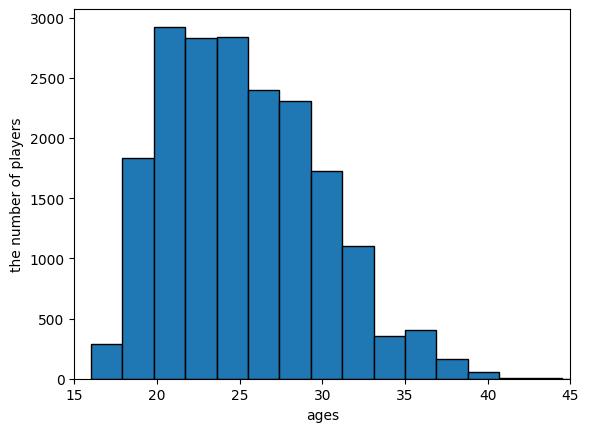

In [116]:
ages = ds['age']
plt.hist(ages, bins= 20, edgecolor='black')
plt.xlim(15, 45)
plt.xlabel('ages')
plt.ylabel('the number of players')
plt.show()

In [87]:
average = ds['age'].mean()
print(average)

25.210821768283175


In [120]:
ages = ds.groupby('age').size()
most_ages = ages.nlargest(10)
print(most_ages)

age
21    1547
22    1446
24    1442
25    1394
23    1387
20    1377
27    1200
26    1197
29    1178
28    1129
dtype: int64


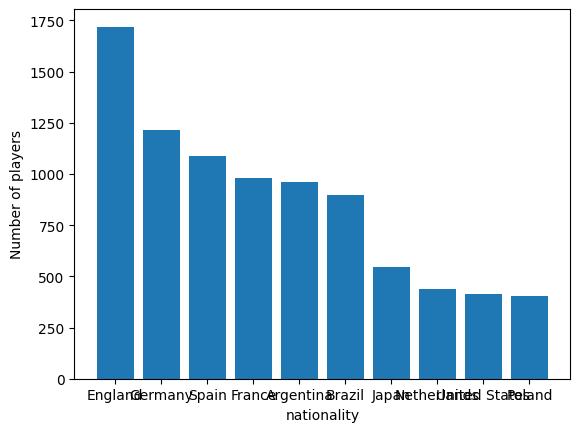

In [121]:
countries = ds.groupby('nationality_name').size()
most_countries = countries.nlargest(10)
plt.bar(most_countries.index, most_countries)
plt.xlabel('nationality')
plt.ylabel('Number of players')
plt.show()

In [122]:
clubs = ds.groupby('club_name').size()
most_clubs = clubs.nlargest(10)
print(most_clubs)

club_name
Arsenal                     33
Borussia Mönchengladbach    33
Brentford                   33
Brighton & Hove Albion      33
Burnley                     33
CA Osasuna                  33
Chelsea                     33
Crystal Palace              33
ESTAC Troyes                33
Everton                     33
dtype: int64


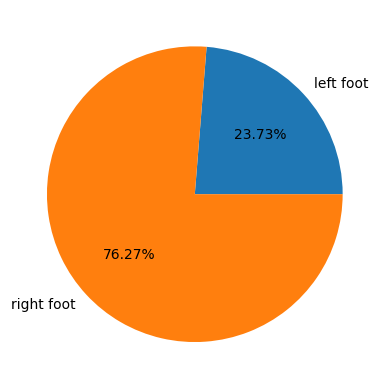

In [123]:
left_players = ds[ds['preferred_foot'] == 'Left']['sofifa_id'].count()
right_players = ds[ds['preferred_foot'] == 'Right']['sofifa_id'].count()
plt.pie([left_players, right_players], labels=['left foot', 'right foot'], autopct='%1.2f%%')
plt.show()

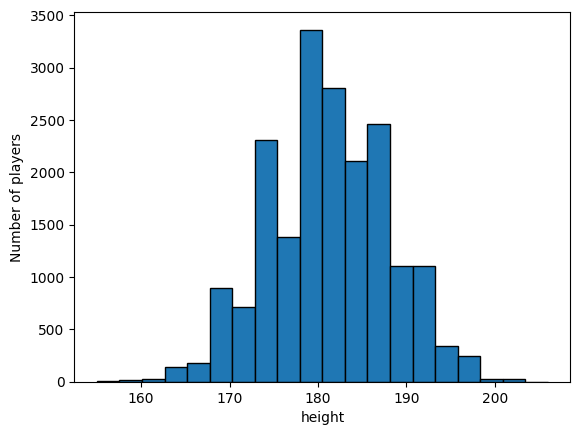

In [124]:
heights = ds['height_cm']
plt.hist(heights, bins=20, edgecolor='black')
plt.xlabel('height')
plt.ylabel('Number of players')
plt.show()

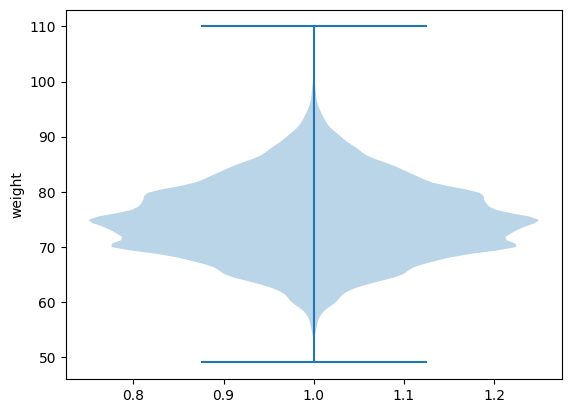

In [140]:
weights = ds['weight_kg']
plt.violinplot(weights)
plt.ylabel('weight')
plt.show()

## Overall Ratings
- What is the distribution of Overall ratings?
- Which players have the highest Overall?
- Which clubs have the highest average Overall rating?
- Which national teams have the highest average Overall?
- What is the average Overall by age?
- Which positions have the highest average Overall?
- Visualizations:
    - Histogram
    - Boxplot
    - Violin plot

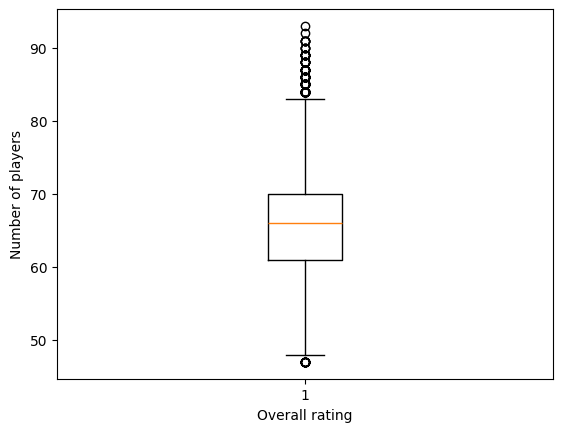

In [141]:
overall = ds['overall']
plt.boxplot(overall)
plt.xlabel('Overall rating')
plt.ylabel('Number of players')
plt.show()

In [128]:
average_overall_for_clubs = ds.groupby('club_name')['overall'].mean()
top10_average_overall_for_clubs = average_overall_for_clubs.nlargest(10)
print(top10_average_overall_for_clubs)

club_name
Juventus               79.961538
Paris Saint-Germain    79.454545
Inter                  78.857143
FC Bayern München      78.071429
Manchester United      78.000000
Real Madrid CF         77.757576
Napoli                 77.500000
Atalanta               77.480000
Real Sociedad          77.280000
SL Benfica             76.931034
Name: overall, dtype: float64


In [129]:
average_overall_for_nations = ds.groupby('nationality_name')['overall'].mean()
top10_average_overall_for_nations = average_overall_for_nations.nlargest(10)
print(top10_average_overall_for_nations)

nationality_name
Tanzania                    74.000000
Libya                       73.333333
Mozambique                  73.000000
Central African Republic    72.500000
Egypt                       72.250000
Fiji                        72.000000
Syria                       72.000000
Gabon                       71.166667
Brazil                      70.851728
Czech Republic              70.682692
Name: overall, dtype: float64


In [130]:
average_overall_for_ages= ds.groupby('age')['overall'].mean()
top10_average_overall_for_ages = average_overall_for_ages.nlargest(10)
print(top10_average_overall_for_ages)

age
43    71.666667
34    69.949153
33    69.788462
35    69.406977
30    69.002220
32    68.993691
29    68.977080
31    68.887273
38    68.661290
37    68.628571
Name: overall, dtype: float64


In [135]:
players = ds.assign(player_positions = ds['player_positions'].str.split(', ')).explode('player_positions')
average_overall_for_positions= players.groupby('player_positions')['overall'].mean()
top10_average_overall_for_positions = average_overall_for_positions.nlargest(10)
print(top10_average_overall_for_positions)

player_positions
CF     68.316372
LW     66.898614
RWB    66.849015
CDM    66.775050
CAM    66.750442
LWB    66.721545
LM     66.700119
RM     66.633265
RW     66.462457
CM     66.336346
Name: overall, dtype: float64
